<a href="https://colab.research.google.com/github/maximofernandezriera/examen-ifc33w/blob/main/solucion-examen-d-v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.png" alt="Open In Colab"/></a>

# Repaso del examen: modelo D-V4 — la biblioteca de Lucía

Lucía es la bibliotecaria del barrio. Cada día presta y recoge libros, los coloca en las estanterías y avisa a quien se retrasa al devolverlos. Para ahorrar tiempo, se ha escrito pequeños programas en Python que le ayudan con estas tareas. En los strings de una estantería, `N` es una novela, `C` un cómic y `.` un hueco libre.

## Cómo se ha corregido

- El examen suma **30 puntos**: A, 8; B, 11; C, 11.
- Los errores de sintaxis no restan puntos.
- Se aceptan respuestas equivalentes con otro formato (por ejemplo, `NNCN` con comillas o «3 multados» en vez de «Multados: 3»).
- En C, la idea correcta puntúa aunque el código no funcione del todo.
- Si no hay código pero los resultados de los ejemplos son correctos, se concede 1 punto.

## Caja de herramientas visual

Ejecutad esta celda una sola vez. Prepara la pizarra, las estanterías, el plano del carro y las tablas que usaremos durante el repaso.

In [1]:
#@title Caja de herramientas visual
import doctest
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import HTML, display

FONDO_PIZARRA = "#164638"
TIZA = "#f3f0df"
TIZA_AMARILLA = "#ffe36e"
TIZA_AZUL = "#a9d7ef"

def dibujar_pizarra(titulo, lineas, ancho=10, alto=3.3, guardar=None):
    """Dibuja una idea con texto y flechas sobre fondo de pizarra."""
    fig, ax = plt.subplots(figsize=(ancho, alto), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.045, 0.91, titulo, color=TIZA_AMARILLA, fontsize=17,
            fontweight="bold", family="DejaVu Sans Mono", va="top")
    cantidad = max(1, len(lineas))
    paso = 0.77 / cantidad
    tamano = 14 if cantidad <= 4 else 12
    for numero, linea in enumerate(lineas):
        if isinstance(linea, tuple):
            texto, color = linea
        else:
            texto, color = linea, TIZA
        ax.text(0.055, 0.78 - numero * paso, texto, color=color,
                fontsize=tamano, family="DejaVu Sans Mono", va="top",
                wrap=True)
    fig.tight_layout(pad=0.5)
    if guardar:
        fig.savefig(guardar, dpi=100, facecolor=FONDO_PIZARRA,
                    bbox_inches="tight")
    display(fig)
    plt.close(fig)

def dibujar_estante(estante, marcar=(), titulo=""):
    """Dibuja las casillas de un estante con los índices debajo."""
    fig, ax = plt.subplots(figsize=(max(5, 1.15 * len(estante)), 2.2), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.text(0.05, 0.94, titulo, transform=ax.transAxes, color=TIZA_AMARILLA,
            fontsize=15, fontweight="bold", family="DejaVu Sans Mono", va="top")
    for i, letra in enumerate(estante):
        resaltada = i in marcar
        ax.add_patch(Rectangle((i, 0), 1, 1,
                               facecolor="#205b49",
                               edgecolor=TIZA_AMARILLA if resaltada else TIZA,
                               linewidth=2.5 if resaltada else 1.5))
        ax.text(i + 0.5, 0.56, letra, ha="center", va="center",
                fontsize=20, color=TIZA_AMARILLA if resaltada else TIZA,
                family="DejaVu Sans Mono", fontweight="bold")
        ax.text(i + 0.5, -0.2, str(i), ha="center", va="center",
                fontsize=12, color=TIZA)
    ax.set_xlim(-0.15, max(1, len(estante)) + 0.15)
    ax.set_ylim(-0.55, 1.05)
    ax.axis("off")
    display(fig)
    plt.close(fig)

def dibujar_estantes_doble(antes, despues, titulo):
    """Compara dos estantes en la misma pizarra."""
    fig, ax = plt.subplots(figsize=(10, 3.1), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.03, 0.94, titulo, transform=ax.transAxes, color=TIZA_AMARILLA,
            fontsize=16, fontweight="bold", family="DejaVu Sans Mono", va="top")
    ancho = max(len(antes), len(despues))
    for fila, (etiqueta, estante) in enumerate((("antes", antes), ("después", despues))):
        y = 0.60 - fila * 0.40
        ax.text(0.04, y + 0.10, etiqueta, transform=ax.transAxes,
                color=TIZA_AZUL, fontsize=13, family="DejaVu Sans Mono")
        for i, letra in enumerate(estante):
            x = 0.21 + 0.73 * i / max(1, ancho)
            w = 0.68 / max(1, ancho)
            ax.add_patch(Rectangle((x, y - 0.05), w, 0.23,
                                   transform=ax.transAxes,
                                   facecolor="#205b49",
                                   edgecolor=TIZA, linewidth=1.2))
            ax.text(x + w / 2, y + 0.065, letra, transform=ax.transAxes,
                    ha="center", va="center", fontsize=15, color=TIZA_AMARILLA,
                    family="DejaVu Sans Mono", fontweight="bold")
    display(fig)
    plt.close(fig)

def tabla_html(filas, columnas):
    """Construye una tabla estática para seguir una vuelta cada vez."""
    estilo = "border:1px solid #b8cbbf;padding:6px 14px;text-align:center;font-size:16px"
    cabecera = "".join(
        f'<th style="{estilo};background:#205b49;color:#fff">{c}</th>'
        for c in columnas
    )
    filas_html = "".join(
        "<tr>" + "".join(
            f'<td style="{estilo};color:#18382e">{fila[c]}</td>'
            for c in columnas
        ) + "</tr>"
        for fila in filas
    )
    return HTML(
        '<table style="border-collapse:collapse">'
        f"<tr>{cabecera}</tr>{filas_html}</table>"
    )

def traza_pasos(filas, columnas, pausa=0):
    """Presenta los datos de cada vuelta en orden."""
    display(tabla_html(filas, columnas))

def dibujar_tabla_pizarra(titulo, columnas, filas, guardar=None):
    """Dibuja una tabla de seguimiento legible en la pizarra."""
    fig, ax = plt.subplots(figsize=(10, max(2.8, 0.48 * (len(filas) + 2))), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.5, 0.96, titulo, transform=ax.transAxes, ha="center", va="top",
            color=TIZA_AMARILLA, fontsize=15, fontweight="bold",
            family="DejaVu Sans Mono")
    izquierda, derecha = 0.05, 0.95
    arriba, abajo = 0.82, 0.08
    ancho = (derecha - izquierda) / len(columnas)
    alto = (arriba - abajo) / (len(filas) + 1)
    for r in range(len(filas) + 2):
        y = arriba - r * alto
        ax.plot([izquierda, derecha], [y, y], transform=ax.transAxes,
                color=TIZA, linewidth=1)
    for c in range(len(columnas) + 1):
        x = izquierda + c * ancho
        ax.plot([x, x], [abajo, arriba], transform=ax.transAxes,
                color=TIZA, linewidth=1)
    tabla = [columnas] + filas
    for r, fila in enumerate(tabla):
        for c, valor in enumerate(fila):
            x = izquierda + (c + 0.5) * ancho
            y = arriba - (r + 0.5) * alto
            ax.text(x, y, str(valor), transform=ax.transAxes, ha="center",
                    va="center", color=TIZA_AMARILLA if r == 0 else TIZA,
                    fontsize=12, family="DejaVu Sans Mono")
    if guardar:
        fig.savefig(guardar, dpi=100, facecolor=FONDO_PIZARRA,
                    bbox_inches="tight")
    display(fig)
    plt.close(fig)

def dibujar_plano(ruta, titulo, guardar=None):
    """Plano en cuadrícula estilo pizarra con el recorrido del carro."""
    movimientos = {"N": (0, 1), "S": (0, -1), "E": (1, 0), "O": (-1, 0)}
    fig, ax = plt.subplots(figsize=(7.5, 4.8), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.set_xlim(-3.6, 3.6)
    ax.set_ylim(-2.9, 3.7)
    ax.set_aspect("equal")
    for gx in range(-3, 4):
        ax.axvline(gx, color="#3f6b5b", linewidth=0.7)
    for gy in range(-2, 4):
        ax.axhline(gy, color="#3f6b5b", linewidth=0.7)
    ax.axhline(0, color=TIZA, linewidth=1.2)
    ax.axvline(0, color=TIZA, linewidth=1.2)
    ax.set_xticks(range(-3, 4))
    ax.set_yticks(range(-2, 4))
    ax.tick_params(colors=TIZA, labelsize=9)
    for spine in ax.spines.values():
        spine.set_color(TIZA)
    ax.set_xlabel("x   (O  \u2190     \u2192  E)", color=TIZA, fontsize=10,
                  family="DejaVu Sans Mono")
    ax.set_ylabel("y   (S  \u2193     \u2191  N)", color=TIZA, fontsize=10,
                  family="DejaVu Sans Mono")
    ax.set_title(titulo, color=TIZA_AMARILLA, fontsize=13, fontweight="bold",
                 family="DejaVu Sans Mono")
    ax.plot(0, 0, marker="s", markersize=12, color=TIZA_AZUL)
    ax.annotate("mostrador\n(0, 0)", (0, 0), (0.3, -1.15), color=TIZA_AZUL,
                fontsize=9, family="DejaVu Sans Mono")
    x, y = 0, 0
    for paso, letra in enumerate(ruta, 1):
        dx, dy = movimientos[letra]
        ax.annotate("", xy=(x + dx, y + dy), xytext=(x, y),
                    arrowprops={"arrowstyle": "-|>", "color": TIZA_AMARILLA,
                                "linewidth": 2})
        ax.text(x + dx / 2 + (0.16 if dx == 0 else 0),
                y + dy / 2 + (0.14 if dy == 0 else 0),
                f"{paso}:{letra}", color=TIZA, fontsize=9,
                family="DejaVu Sans Mono")
        x, y = x + dx, y + dy
    ax.plot(x, y, marker="o", markersize=9, color=TIZA_AMARILLA)
    desfase = 0.3 if movimientos[ruta[-1]][1] >= 0 else -0.9
    ax.annotate(f"acaba en [{x}, {y}]", (x, y), (x + 0.4, y + desfase),
                color=TIZA_AMARILLA, fontsize=10, family="DejaVu Sans Mono")
    if guardar:
        fig.savefig(guardar, dpi=100, facecolor=FONDO_PIZARRA,
                    bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("Caja lista: pizarra, estantes, plano y tablas.")


Caja lista: pizarra, estantes, plano y tablas.


## A1 · `return` frente a `print` (2 puntos)

### Enunciado exacto

Lucía calcula la multa por retraso de dos maneras distintas (2 euros por día). ¿Cuánto valen a y b después de ejecutar este código? (2 ptos)

```python
def multa_a(dias):
    return dias * 2

def multa_b(dias):
    print(dias * 2)

a = multa_a(5)
b = multa_b(5)
```

a) `a` vale 10 y `b` vale 10  b) `a` vale `None` y `b` vale 10<br>c) `a` vale 10 y `b` vale `None`  d) los dos valen `None`

### Pizarra

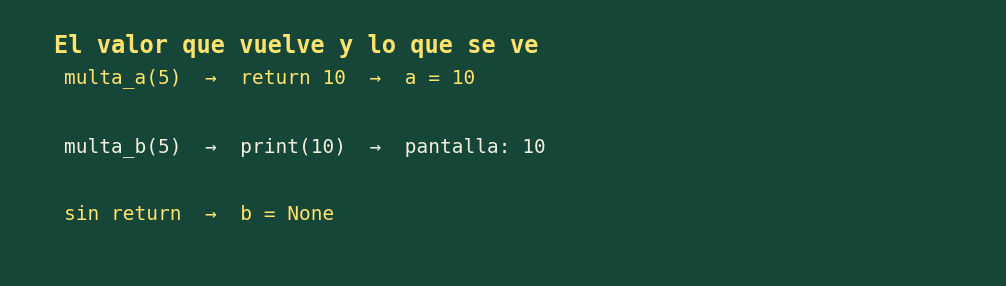

In [2]:
dibujar_pizarra(
    'El valor que vuelve y lo que se ve',
    [('multa_a(5)  →  return 10  →  a = 10', TIZA_AMARILLA),
    ('multa_b(5)  →  print(10)  →  pantalla: 10', TIZA),
    ('sin return  →  b = None', TIZA_AMARILLA)],
    ancho=10, alto=2.8,
)

In [3]:
def multa_a(dias):
    return dias * 2

def multa_b(dias):
    print(dias * 2)

a = multa_a(5)
b = multa_b(5)

10


**Paso a paso.** `multa_a` devuelve `5 * 2`, así que `a` vale `10`. `multa_b` muestra `10` en pantalla, pero no tiene `return`; Python devuelve `None` cuando una función termina sin devolver un valor. Por eso `b` vale `None`. La respuesta es **c)**.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20multa_a%28dias%29%3A%0A%20%20%20%20return%20dias%20%2A%202%0A%0Adef%20multa_b%28dias%29%3A%0A%20%20%20%20print%28dias%20%2A%202%29%0A%0Aa%20%3D%20multa_a%285%29%0Ab%20%3D%20multa_b%285%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta c: distingue el valor devuelto de lo que se imprime. | 2 |
| Una respuesta incorrecta no resta. | 0 de resta |

#### Errores frecuentes

- Tomar el `10` que aparece en pantalla como el valor asignado a `b`.
- Confundir `print` con `return`.

## A2 · Diccionario de préstamos (2 puntos)

### Enunciado exacto

Lucía guarda en un diccionario cuántos libros tiene prestados cada socio. Leo se lleva un libro más y Eva se hace socia y se lleva 3. ¿Qué imprime este código? (2 ptos)

```python
prestamos = {"Ana": 2, "Leo": 1}
prestamos["Leo"] = prestamos["Leo"] + 1
prestamos["Eva"] = 3
print(len(prestamos), prestamos["Leo"])
```

a) 2 2  b) 3 2  c) 3 1  d) 6 2

### Pizarra

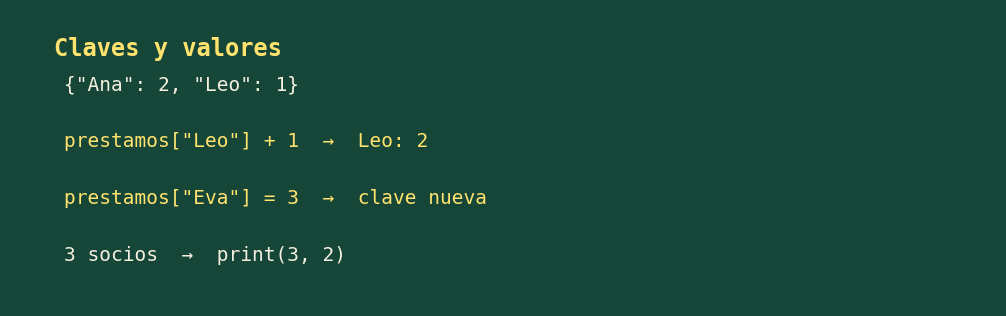

In [4]:
dibujar_pizarra(
    'Claves y valores',
    [('{"Ana": 2, "Leo": 1}', TIZA),
    ('prestamos["Leo"] + 1  →  Leo: 2', TIZA_AMARILLA),
    ('prestamos["Eva"] = 3  →  clave nueva', TIZA_AMARILLA),
    ('3 socios  →  print(3, 2)', TIZA)],
    ancho=10, alto=3.1,
)

In [5]:
prestamos = {"Ana": 2, "Leo": 1}
prestamos["Leo"] = prestamos["Leo"] + 1
prestamos["Eva"] = 3
print(len(prestamos), prestamos["Leo"])

3 2


**Paso a paso.** El diccionario guarda parejas clave → valor. `prestamos['Leo'] + 1` deja a Leo con 2. `prestamos['Eva'] = 3` crea una clave nueva: el diccionario pasa a tener 3 socios. El `print` muestra `3 2`: **b)**.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=prestamos%20%3D%20%7B%22Ana%22%3A%202%2C%20%22Leo%22%3A%201%7D%0Aprestamos%5B%22Leo%22%5D%20%3D%20prestamos%5B%22Leo%22%5D%20%2B%201%0Aprestamos%5B%22Eva%22%5D%20%3D%203%0Aprint%28len%28prestamos%29%2C%20prestamos%5B%22Leo%22%5D%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta b: entiende las claves y los valores del diccionario. | 2 |
| Una respuesta incorrecta no resta. | 0 de resta |

#### Errores frecuentes

- Olvidar que `Eva` es una clave nueva y quedarse en 2 socios (opción a).
- Responder el valor de Leo antes de sumar: `3 1` (opción c).
- Sumar los libros de todos en lugar de contar las claves (opción d).

## A3 · Contador y condición (2 puntos)

### Enunciado exacto

En el club de lectura, cada novela leída da 1 sello en el carné. ¿Qué imprime este código? (2 ptos)

```python
sellos = 0
for libro in ["novela", "revista", "novela"]:
    if libro == "novela":
        sellos = sellos + 1
print(sellos)
```

a) 2  b) 0  c) 3  d) 1

### Pizarra

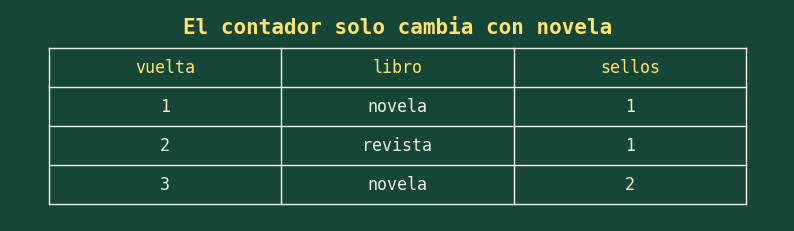

In [6]:
dibujar_tabla_pizarra("El contador solo cambia con novela", ["vuelta", "libro", "sellos"], [["1", "novela", "1"], ["2", "revista", "1"], ["3", "novela", "2"]])

In [7]:
sellos = 0
for libro in ["novela", "revista", "novela"]:
    if libro == "novela":
        sellos = sellos + 1
print(sellos)

2


**Paso a paso.** El bucle visita tres libros. La condición se cumple en la primera y en la tercera vuelta; el contador pasa de 0 a 1 y luego a 2. La revista no lo cambia. Se imprime `2`: **a)**.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=sellos%20%3D%200%0Afor%20libro%20in%20%5B%22novela%22%2C%20%22revista%22%2C%20%22novela%22%5D%3A%0A%20%20%20%20if%20libro%20%3D%3D%20%22novela%22%3A%0A%20%20%20%20%20%20%20%20sellos%20%3D%20sellos%20%2B%201%0Aprint%28sellos%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta a: cuenta solo las novelas. | 2 |
| Una respuesta incorrecta no resta. | 0 de resta |

#### Errores frecuentes

- Sumar en las tres vueltas sin comprobar el `if` (opción c).
- Contar vueltas en lugar de contar las veces que se cumple la condición.

## A4 · `append` y longitud (2 puntos)

### Enunciado exacto

Lucía apunta los libros que presta durante la mañana. ¿Qué imprime este código? (2 ptos)

```python
prestados = ["Momo", "Matilda"]
prestados.append("Dune")
print(len(prestados))
```

a) Dune  b) 2  c) 4  d) 3

### Pizarra

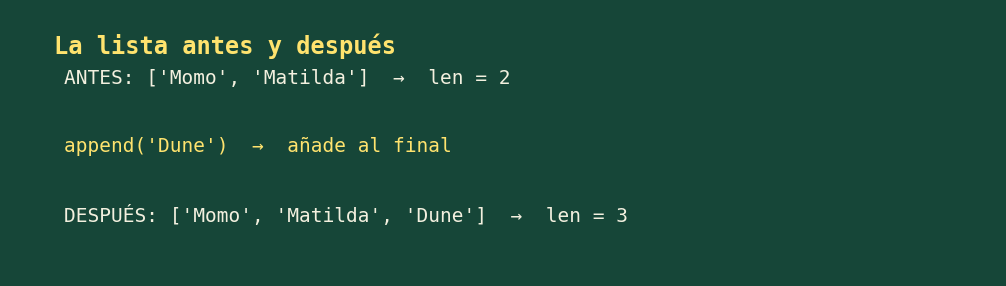

In [8]:
dibujar_pizarra(
    'La lista antes y después',
    [("ANTES: ['Momo', 'Matilda']  →  len = 2", TIZA),
    ("append('Dune')  →  añade al final", TIZA_AMARILLA),
    ("DESPUÉS: ['Momo', 'Matilda', 'Dune']  →  len = 3", TIZA)],
    ancho=10, alto=2.8,
)

In [9]:
prestados = ["Momo", "Matilda"]
prestados.append("Dune")
print(len(prestados))

3


**Paso a paso.** `append` agrega `Dune` al final de la lista. `len` cuenta los elementos después de ese cambio: hay 3. La respuesta es **d) 3**.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=prestados%20%3D%20%5B%22Momo%22%2C%20%22Matilda%22%5D%0Aprestados.append%28%22Dune%22%29%0Aprint%28len%28prestados%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta d: comprende `append` y `len`. | 2 |
| Una respuesta incorrecta no resta. | 0 de resta |

#### Errores frecuentes

- Contar los elementos antes de ejecutar `append` (opción b).
- Elegir `Dune`, que es el elemento añadido y no la longitud (opción a).

## B1 · Tabla de seguimiento (3 puntos)

### Enunciado exacto

B1. (3 pts) Lucía revisa los libros devueltos: la lista indica cuántos días de retraso trae cada uno. Cuenta cuántos libros ha revisado y pone multa a los que llegan con 3 días o más. Completa la tabla con el valor de las variables al final de cada vuelta y escribe lo que imprime.

```python
def revisar(retrasos):
    multados = 0
    revisados = 0
    for d in retrasos:
        revisados = revisados + 1
        if d >= 3:
            multados = multados + 1
    print("Multados:", multados)
    print("Revisados:", revisados)

revisar([4, 1, 5, 0, 6])
```

### Pizarra

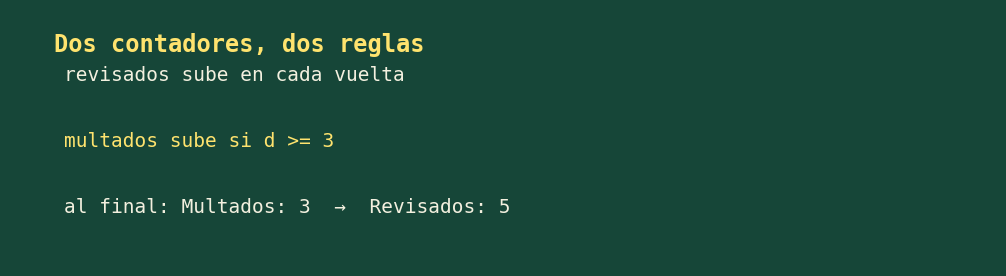

In [10]:
dibujar_pizarra(
    'Dos contadores, dos reglas',
    [('revisados sube en cada vuelta', TIZA),
    ('multados sube si d >= 3', TIZA_AMARILLA),
    ('al final: Multados: 3  →  Revisados: 5', TIZA)],
    ancho=10, alto=2.7,
)

In [11]:
def revisar(retrasos):
    multados = 0
    revisados = 0
    for d in retrasos:
        revisados = revisados + 1
        if d >= 3:
            multados = multados + 1
    print("Multados:", multados)
    print("Revisados:", revisados)

revisar([4, 1, 5, 0, 6])

Multados: 3
Revisados: 5


In [12]:
filas_b1 = [{'Vuelta': '1', 'd': '4', 'multados': '1', 'revisados': '1'}, {'Vuelta': '2', 'd': '1', 'multados': '1', 'revisados': '2'}, {'Vuelta': '3', 'd': '5', 'multados': '2', 'revisados': '3'}, {'Vuelta': '4', 'd': '0', 'multados': '2', 'revisados': '4'}, {'Vuelta': '5', 'd': '6', 'multados': '3', 'revisados': '5'}]
traza_pasos(filas_b1, ["Vuelta", "d", "multados", "revisados"])

Vuelta,d,multados,revisados
1,4,1,1
2,1,1,2
3,5,2,3
4,0,2,4
5,6,3,5


**Paso a paso.** Primero, `revisados` aumenta una vez en cada vuelta. Después se comprueba `d >= 3`: las vueltas 1, 3 y 5 suman una multa. La tabla termina con `multados = 3` y `revisados = 5`; los dos `print` están después del bucle.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20revisar%28retrasos%29%3A%0A%20%20%20%20multados%20%3D%200%0A%20%20%20%20revisados%20%3D%200%0A%20%20%20%20for%20d%20in%20retrasos%3A%0A%20%20%20%20%20%20%20%20revisados%20%3D%20revisados%20%2B%201%0A%20%20%20%20%20%20%20%20if%20d%20%3E%3D%203%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20multados%20%3D%20multados%20%2B%201%0A%20%20%20%20print%28%22Multados%3A%22%2C%20multados%29%0A%20%20%20%20print%28%22Revisados%3A%22%2C%20revisados%29%0A%0Arevisar%28%5B4%2C%201%2C%205%2C%200%2C%206%5D%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Tabla: 0,4 por cada fila completa. | 2 |
| Se acepta crédito parcial por columna si una fila está parcialmente bien. | — |
| Salida `Multados: 3`. | 0,5 |
| Salida `Revisados: 5`. | 0,5 |

#### Errores frecuentes

- Escribir `None` en lugar de las líneas que muestran los `print`.
- Omitir el texto `Multados:` o `Revisados:` en las salidas.
- Aumentar `multados` también cuando `d` es menor que 3.

## B2 · Espacio y `return` temprano (4 puntos)

### Enunciado exacto

B2. (4 pts) Esta función calcula cuántos libros caben, en orden, en el espacio libre de una balda: la lista indica el grosor de cada libro en centímetros y espacio, los centímetros libres. Escribe exactamente lo que imprime el programa y responde: ¿cuántas vueltas da el bucle en la primera llamada? (1 pto cada línea impresa y 1 pto la pregunta)

```python
def caben(grosores, espacio):
    libros = 0
    for g in grosores:
        if g > espacio:
            return libros
        espacio = espacio - g
        libros = libros + 1
    return libros

print(caben([2, 3], 4))
print(caben([1, 1], 5))
print(caben([7], 5))
```

### Pizarra

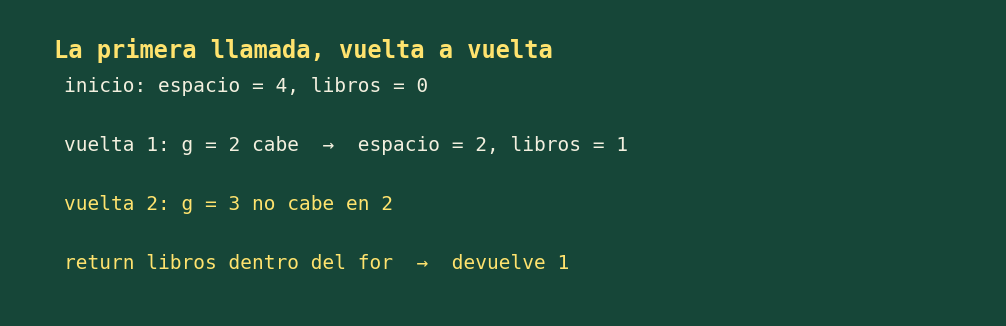

In [13]:
dibujar_pizarra(
    'La primera llamada, vuelta a vuelta',
    [('inicio: espacio = 4, libros = 0', TIZA),
    ('vuelta 1: g = 2 cabe  →  espacio = 2, libros = 1', TIZA),
    ('vuelta 2: g = 3 no cabe en 2', TIZA_AMARILLA),
    ('return libros dentro del for  →  devuelve 1', TIZA_AMARILLA)],
    ancho=10, alto=3.2,
)

In [14]:
def caben(grosores, espacio):
    libros = 0
    for g in grosores:
        if g > espacio:
            return libros
        espacio = espacio - g
        libros = libros + 1
    return libros

print(caben([2, 3], 4))
print(caben([1, 1], 5))
print(caben([7], 5))

1
2
0


In [15]:
filas_b2 = [{'Vuelta': '1', 'g': '2', 'espacio antes': '4', '¿cabe?': 'sí', 'libros': '1'}, {'Vuelta': '2', 'g': '3', 'espacio antes': '2', '¿cabe?': 'no → return', 'libros': '1'}]
traza_pasos(filas_b2, ["Vuelta", "g", "espacio antes", "¿cabe?", "libros"])

Vuelta,g,espacio antes,¿cabe?,libros
1,2,4,sí,1
2,3,2,no → return,1


**Paso a paso.** En la primera llamada, el libro de grosor 2 cabe en 4: quedan 2 cm y `libros` pasa a 1. El bucle llega a la segunda vuelta con `g = 3`; no cabe en los 2 cm. El `return libros` de dentro termina la función y devuelve 1. Por eso son **2 vueltas**. En la segunda llamada caben los dos libros y devuelve 2; en la tercera el libro no cabe desde el principio y devuelve 0.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20caben%28grosores%2C%20espacio%29%3A%0A%20%20%20%20libros%20%3D%200%0A%20%20%20%20for%20g%20in%20grosores%3A%0A%20%20%20%20%20%20%20%20if%20g%20%3E%20espacio%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20return%20libros%0A%20%20%20%20%20%20%20%20espacio%20%3D%20espacio%20-%20g%0A%20%20%20%20%20%20%20%20libros%20%3D%20libros%20%2B%201%0A%20%20%20%20return%20libros%0A%0Aprint%28caben%28%5B2%2C%203%5D%2C%204%29%29%0Aprint%28caben%28%5B1%2C%201%5D%2C%205%29%29%0Aprint%28caben%28%5B7%5D%2C%205%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Primera línea impresa: `1`. | 1 |
| Segunda línea impresa: `2`. | 1 |
| Tercera línea impresa: `0`. | 1 |
| Primera llamada: 2 vueltas. | 1 |

#### Errores frecuentes

- Contar el `return` como si el bucle continuara con más elementos.
- No descontar el grosor que sí cabe antes de comprobar la siguiente vuelta.

## B3 · Impresión dentro y fuera (2 puntos)

### Enunciado exacto

B3. (2 pts) Lucía aparta todo lo que llega menos las revistas para ponerle el sello de la biblioteca. Escribe exactamente lo que aparece en pantalla al ejecutar este programa. (1 pto la lista, 0,5 ptos cada una de las otras dos líneas)

```python
def sellar(lote):
    sellados = []
    for libro in lote:
        if libro != "revista":
            sellados.append(libro)
    print(len(lote))
    return sellados

r = sellar(["novela", "revista", "comic"])
print(r)
print(len(r))
```

### Pizarra

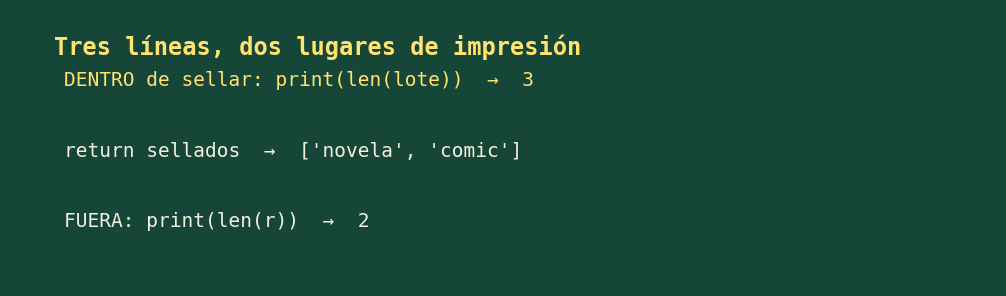

In [16]:
dibujar_pizarra(
    'Tres líneas, dos lugares de impresión',
    [('DENTRO de sellar: print(len(lote))  →  3', TIZA_AMARILLA),
    ("return sellados  →  ['novela', 'comic']", TIZA),
    ('FUERA: print(len(r))  →  2', TIZA)],
    ancho=10, alto=2.9,
)

In [17]:
def sellar(lote):
    sellados = []
    for libro in lote:
        if libro != "revista":
            sellados.append(libro)
    print(len(lote))
    return sellados

r = sellar(["novela", "revista", "comic"])
print(r)
print(len(r))

3
['novela', 'comic']
2


**Paso a paso.** Al llamar a `sellar`, el `print` que está dentro muestra la longitud de `lote`, que es 3. La función devuelve la lista sin `revista`. Después, fuera de la función, el programa muestra esa lista y su longitud, 2.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20sellar%28lote%29%3A%0A%20%20%20%20sellados%20%3D%20%5B%5D%0A%20%20%20%20for%20libro%20in%20lote%3A%0A%20%20%20%20%20%20%20%20if%20libro%20%21%3D%20%22revista%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20sellados.append%28libro%29%0A%20%20%20%20print%28len%28lote%29%29%0A%20%20%20%20return%20sellados%0A%0Ar%20%3D%20sellar%28%5B%22novela%22%2C%20%22revista%22%2C%20%22comic%22%5D%29%0Aprint%28r%29%0Aprint%28len%28r%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Lista `['novela', 'comic']`. | 1 |
| Primera línea `3`. | 0,5 |
| Última línea `2`. | 0,5 |

#### Errores frecuentes

- Olvidar el `3` que imprime la función por dentro.
- Confundir la lista devuelta con el lote original.

## B4 · Construir un string (2 puntos)

### Enunciado exacto

B4. (2 pts) Han llegado novelas nuevas y Lucía coloca una en cada hueco libre de la estantería. Indica exactamente qué imprime cada línea. (1,5 ptos la primera, 0,5 ptos la segunda)

```python
estante = "N.C."
nuevo = ""
vacios = 0
for c in estante:
    if c == ".":
        nuevo = nuevo + "N"
        vacios = vacios + 1
    else:
        nuevo = nuevo + c

print(nuevo)
print(vacios)
```

### Pizarra

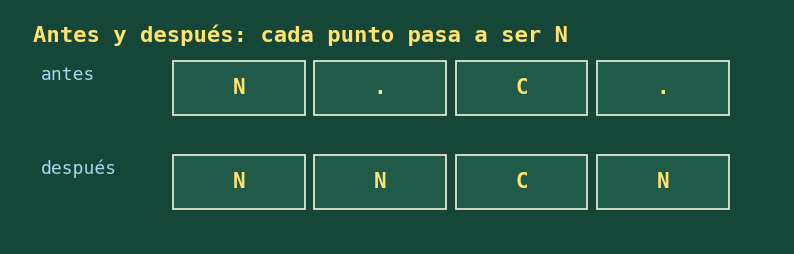

In [18]:
dibujar_estantes_doble("N.C.", "NNCN", "Antes y después: cada punto pasa a ser N")

In [19]:
estante = "N.C."
nuevo = ""
vacios = 0
for c in estante:
    if c == ".":
        nuevo = nuevo + "N"
        vacios = vacios + 1
    else:
        nuevo = nuevo + c

print(nuevo)
print(vacios)

NNCN
2


**Paso a paso.** El `for` recorre las letras de `N.C.`. Copia la primera `N`, cambia `.` por `N`, copia `C` y cambia el último `.` por `N`. El nuevo estante es `NNCN`; hay 2 huecos sustituidos. Se imprimen esas dos líneas.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=estante%20%3D%20%22N.C.%22%0Anuevo%20%3D%20%22%22%0Avacios%20%3D%200%0Afor%20c%20in%20estante%3A%0A%20%20%20%20if%20c%20%3D%3D%20%22.%22%3A%0A%20%20%20%20%20%20%20%20nuevo%20%3D%20nuevo%20%2B%20%22N%22%0A%20%20%20%20%20%20%20%20vacios%20%3D%20vacios%20%2B%201%0A%20%20%20%20else%3A%0A%20%20%20%20%20%20%20%20nuevo%20%3D%20nuevo%20%2B%20c%0A%0Aprint%28nuevo%29%0Aprint%28vacios%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Primera línea: `NNCN`. | 1,5 |
| Segunda línea: `2`. | 0,5 |

#### Errores frecuentes

- Cambiar letras que no son `.`.
- No conservar el resto del estante en el string nuevo.

## C1 · Devolver posiciones de huecos (4 puntos)

### Enunciado exacto

C1. (4 pts) Huecos libres. Escribe `huecos(estante)`, que devuelve una lista con las posiciones de los huecos libres `.` de la estantería, de izquierda a derecha. La primera posición es la 0.

Pista: recorre las posiciones con `for i in range(len(estante)):` y mira la letra `estante[i]`.

```text
huecos("N..C.")   ->  [1, 2, 4]
huecos("NNC")     ->  []
```

### Pizarra

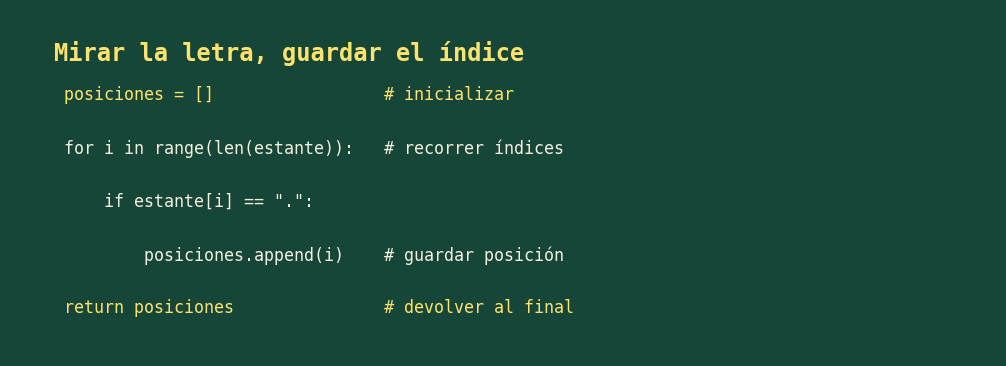

In [20]:
dibujar_pizarra(
    'Mirar la letra, guardar el índice',
    [('posiciones = []                 # inicializar', TIZA_AMARILLA),
    ('for i in range(len(estante)):   # recorrer índices', TIZA),
    ('    if estante[i] == ".":', TIZA),
    ('        posiciones.append(i)    # guardar posición', TIZA),
    ('return posiciones               # devolver al final', TIZA_AMARILLA)],
    ancho=10, alto=3.6,
)

In [21]:
def huecos(estante):
    posiciones = []             # inicializar
    for i in range(len(estante)):   # recorrer
        if estante[i] == ".":
            posiciones.append(i)    # actualizar
    return posiciones

print(huecos("N..C."))
print(huecos("NNC"))

[1, 2, 4]
[]


In [22]:
huecos.__doc__ = """
>>> huecos("N..C.")
[1, 2, 4]
>>> huecos("NNC")
[]
"""
doctest.run_docstring_examples(huecos, globals(), verbose=True)
runner = doctest.DocTestRunner()
for ejemplo in doctest.DocTestFinder().find(huecos, "huecos"):
    runner.run(ejemplo)
resultado = runner.summarize()
assert resultado.failed == 0
print("Ejemplos verificados: huecos")

Finding tests in NoName
Ejemplos verificados: huecos


**Paso a paso.** `range(len(estante))` produce las posiciones 0, 1, 2... En cada posición comprobamos el carácter con `estante[i]`. Si es `.`, añadimos `i` a la lista. Al terminar el recorrido devolvemos la lista de posiciones, no una lista de letras.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20huecos%28estante%29%3A%0A%20%20%20%20posiciones%20%3D%20%5B%5D%20%20%20%20%20%20%20%20%20%20%20%20%20%23%20inicializar%0A%20%20%20%20for%20i%20in%20range%28len%28estante%29%29%3A%20%20%20%23%20recorrer%0A%20%20%20%20%20%20%20%20if%20estante%5Bi%5D%20%3D%3D%20%22.%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20posiciones.append%28i%29%20%20%20%20%23%20actualizar%0A%20%20%20%20return%20posiciones%0Aprint%28huecos%28%22N..C.%22%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Inicializa la lista vacía fuera del bucle. | 1 |
| Recorre por posiciones (`range`/`len` o `enumerate`). | 1 |
| La condición compara `estante[i]` con `"."`. | 1 |
| Añade la posición y devuelve la lista. | 1 |

#### Errores frecuentes

- Comparar el índice `i` con la letra en lugar de mirar `estante[i]`.
- Añadir `estante[i]` o el estante entero en vez de añadir `i`.
- Usar `print` en lugar de `return`.

## C2 · Contar novelas (3 puntos)

### Enunciado exacto

C2. (3 pts) Inventario. Para el inventario, Lucía quiere saber cuántas novelas `N` hay en una estantería. Escribe `contar_novelas(estante)`, que devuelve cuántas novelas hay; los cómics y los huecos no cuentan.

```text
contar_novelas("NN.C")    ->  2
contar_novelas("CCN.N")   ->  2
contar_novelas("")        ->  0
```

### Pizarra

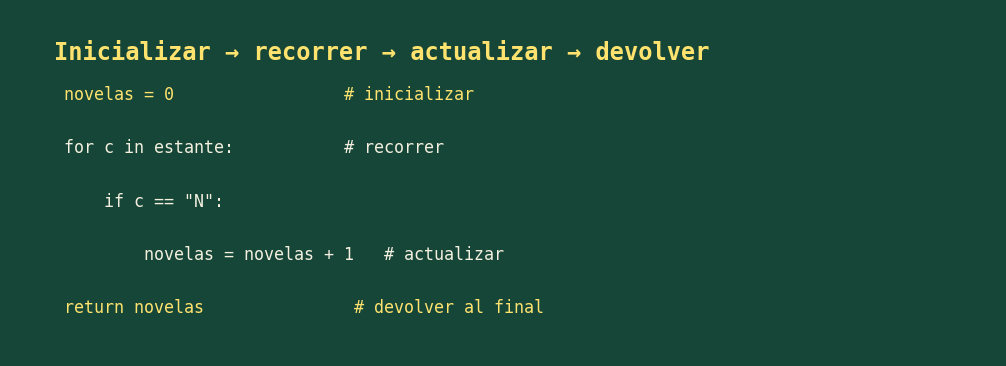

In [23]:
dibujar_pizarra(
    'Inicializar → recorrer → actualizar → devolver',
    [('novelas = 0                 # inicializar', TIZA_AMARILLA),
    ('for c in estante:           # recorrer', TIZA),
    ('    if c == "N":', TIZA),
    ('        novelas = novelas + 1   # actualizar', TIZA),
    ('return novelas               # devolver al final', TIZA_AMARILLA)],
    ancho=10, alto=3.6,
)

In [24]:
def contar_novelas(estante):
    novelas = 0                 # inicializar
    for c in estante:           # recorrer
        if c == "N":
            novelas = novelas + 1   # actualizar
    return novelas

print(contar_novelas("NN.C"))
print(contar_novelas("CCN.N"))
print(contar_novelas(""))

2
2
0


In [25]:
contar_novelas.__doc__ = """
>>> contar_novelas("NN.C")
2
>>> contar_novelas("CCN.N")
2
>>> contar_novelas("")
0
"""
doctest.run_docstring_examples(contar_novelas, globals(), verbose=True)
runner = doctest.DocTestRunner()
for ejemplo in doctest.DocTestFinder().find(contar_novelas, "contar_novelas"):
    runner.run(ejemplo)
resultado = runner.summarize()
assert resultado.failed == 0
print("Ejemplos verificados: contar_novelas")

Finding tests in NoName


Ejemplos verificados: contar_novelas


**Paso a paso.** El contador nace en 0 antes del bucle. El `for` recorre cada carácter; solo cuando `c` es `N` se suma 1. El `return` está al final, fuera del bucle, para devolver el total después de revisar toda la estantería.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20contar_novelas%28estante%29%3A%0A%20%20%20%20novelas%20%3D%200%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%23%20inicializar%0A%20%20%20%20for%20c%20in%20estante%3A%20%20%20%20%20%20%20%20%20%20%20%23%20recorrer%0A%20%20%20%20%20%20%20%20if%20c%20%3D%3D%20%22N%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20novelas%20%3D%20novelas%20%2B%201%20%20%20%23%20actualizar%0A%20%20%20%20return%20novelas%0Aprint%28contar_novelas%28%22NN.C%22%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Inicializa el contador a 0 fuera del bucle. | 1 |
| Recorre la estantería con una condición dentro del bucle. | 1 |
| Suma dentro del bucle y devuelve el total al final. | 1 |
| Si usa `print` en lugar de `return`. | -1 |

#### Errores frecuentes

- Poner `return` dentro del bucle: la función acaba en la primera letra.
- Usar `print` en lugar de `return` cuando el enunciado pide devolver.

## C3 · El carro en cuatro direcciones (4 puntos)

### Enunciado exacto

C3. (4 pts) El carro de devoluciones. Lucía recorre la biblioteca empujando el carro con los libros devueltos para dejarlos en su sitio. El plano de la biblioteca es una cuadrícula: cada casilla tiene dos coordenadas, `x` (izquierda-derecha) e `y` (abajo-arriba). Lucía siempre sale del mostrador, la casilla `(0, 0)`.

La ruta es un string en el que cada letra mueve el carro una casilla:

| Letra | Dirección | Qué cambia |
|---|---|---|
| N | norte (arriba) | y aumenta 1 |
| S | sur (abajo) | y disminuye 1 |
| E | este (derecha) | x aumenta 1 |
| O | oeste (izquierda) | x disminuye 1 |

Por ejemplo, con la ruta `NNE` el carro hace tres movimientos:

| Paso | Letra | x | y |
|---|---|---:|---:|
| inicio |  | 0 | 0 |
| 1 | N | 0 | 1 |
| 2 | N | 0 | 2 |
| 3 | E | 1 | 2 |

Escribe `posicion_final(ruta)`, que devuelve la lista `[x, y]` donde acaba el carro. Si la ruta está vacía, el carro no se mueve.

```text
posicion_final("NNE")    ->  [1, 2]
posicion_final("OOS")    ->  [-2, -1]
posicion_final("NSEO")   ->  [0, 0]
```

### Pizarra

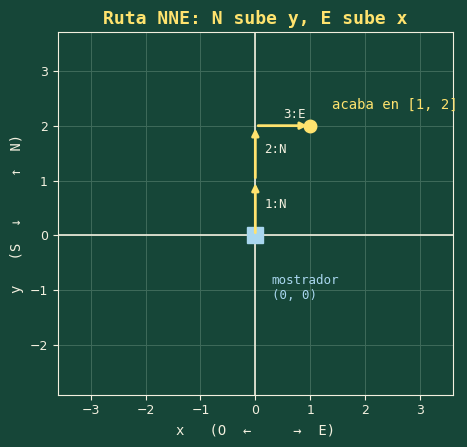

In [26]:
dibujar_plano("NNE", "Ruta NNE: N sube y, E sube x")

In [27]:
def posicion_final(ruta):
    x = 0                       # inicializar
    y = 0
    for paso in ruta:           # recorrer
        if paso == "N":
            y = y + 1           # actualizar
        elif paso == "S":
            y = y - 1
        elif paso == "E":
            x = x + 1
        elif paso == "O":
            x = x - 1
    return [x, y]

print(posicion_final("NNE"))
print(posicion_final("OOS"))
print(posicion_final("NSEO"))

[1, 2]
[-2, -1]
[0, 0]


In [28]:
filas_c3 = [{'Paso': 'inicio', 'Letra': '', 'x': '0', 'y': '0'}, {'Paso': '1', 'Letra': 'N', 'x': '0', 'y': '1'}, {'Paso': '2', 'Letra': 'N', 'x': '0', 'y': '2'}, {'Paso': '3', 'Letra': 'E', 'x': '1', 'y': '2'}]
traza_pasos(filas_c3, ["Paso", "Letra", "x", "y"])

Paso,Letra,x,y
inicio,,0,0
1,N,0,1
2,N,0,2
3,E,1,2


In [29]:
posicion_final.__doc__ = """
>>> posicion_final("NNE")
[1, 2]
>>> posicion_final("OOS")
[-2, -1]
>>> posicion_final("NSEO")
[0, 0]
"""
doctest.run_docstring_examples(posicion_final, globals(), verbose=True)
runner = doctest.DocTestRunner()
for ejemplo in doctest.DocTestFinder().find(posicion_final, "posicion_final"):
    runner.run(ejemplo)
resultado = runner.summarize()
assert resultado.failed == 0
print("Ejemplos verificados: posicion_final")

Finding tests in NoName
Ejemplos verificados: posicion_final


**Paso a paso.** Ahora hay **dos contadores**: `x` se mueve con E (suma) y O (resta); `y` se mueve con N (suma) y S (resta). El bucle procesa la ruta letra a letra y `return [x, y]` devuelve la lista de las dos coordenadas. Si la ruta está vacía, no hay vueltas y se devuelve `[0, 0]`.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20posicion_final%28ruta%29%3A%0A%20%20%20%20x%20%3D%200%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%23%20inicializar%0A%20%20%20%20y%20%3D%200%0A%20%20%20%20for%20paso%20in%20ruta%3A%20%20%20%20%20%20%20%20%20%20%20%23%20recorrer%0A%20%20%20%20%20%20%20%20if%20paso%20%3D%3D%20%22N%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20y%20%3D%20y%20%2B%201%20%20%20%20%20%20%20%20%20%20%20%23%20actualizar%0A%20%20%20%20%20%20%20%20elif%20paso%20%3D%3D%20%22S%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20y%20%3D%20y%20-%201%0A%20%20%20%20%20%20%20%20elif%20paso%20%3D%3D%20%22E%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20x%20%3D%20x%20%2B%201%0A%20%20%20%20%20%20%20%20elif%20paso%20%3D%3D%20%22O%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20x%20%3D%20x%20-%201%0A%20%20%20%20return%20%5Bx%2C%20y%5D%0Aprint%28posicion_final%28%22NNE%22%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Inicializa `x` e `y` a 0 fuera del bucle. | 1 |
| Recorre la ruta con una condición por letra. | 1 |
| Actualiza `x` e `y` dentro del bucle. | 1 |
| Devuelve la lista `[x, y]` al final. | 1 |

#### Errores frecuentes

- Devolver un solo número en lugar de la lista `[x, y]`.
- Sumar la `N` o la `S` a `x`, o la `E`/`O` a `y`.
- Poner `return` dentro del bucle: la ruta se detendría tras la primera letra.
- Usar `print` en lugar de `return`.

# Resumen final

| Ejercicio | Respuesta oficial | Puntos |
|---|---|---:|
| A1 | c) `a = 10`, `b = None` | 2 |
| A2 | b) 3 2 | 2 |
| A3 | a) 2 | 2 |
| A4 | d) 3 | 2 |
| B1 | tabla de 5 filas; `Multados: 3`, `Revisados: 5` | 3 |
| B2 | `1`, `2`, `0`; 2 vueltas en la primera llamada | 4 |
| B3 | `3`; `['novela', 'comic']`; `2` | 2 |
| B4 | `NNCN`; `2` | 2 |
| C1 | `huecos`: [1, 2, 4], [] | 4 |
| C2 | `contar_novelas`: 2, 2, 0 | 3 |
| C3 | `posicion_final`: [1, 2], [-2, -1], [0, 0] | 4 |
| **Total** | **A: 8 · B: 11 · C: 11** | **30** |

## Dudas frecuentes

**¿Por qué `b` vale `None` en A1?**  
`multa_b` imprime el resultado, pero no tiene `return`; por eso no entrega un valor y la asignación recibe `None`.

**¿Por qué en A2 se imprime `3` si el diccionario empezaba con 2 socios?**  
`prestamos['Eva'] = 3` crea una clave nueva: el `len` cuenta las claves y pasan a ser 3.

**¿Por qué son 2 vueltas en B2?**  
El bucle comprueba primero el grosor 2, que cabe, y después el grosor 3, que no cabe en los 2 cm restantes. Esa comprobación sucede en la segunda vuelta.

**¿Por qué C3 devuelve `[1, 2]` y no `3`?**  
El carro se mueve en un plano con dos coordenadas: la función entrega la lista `[x, y]`, no la suma de movimientos.

**¿Me quitan puntos por la sintaxis?**  
No se restan puntos por errores de sintaxis. En C también puntúa la idea correcta aunque el código no funcione del todo.

**¿Se acepta una salida con otro formato?**  
Sí, si el contenido es equivalente: por ejemplo, `NNCN` con comillas o «3 multados» en vez de «Multados: 3».

**¿Qué hago si no escribí código en C?**  
Si los resultados de los ejemplos son correctos, se concede 1 punto.